1. **Nome(s):** Leonardo Silveira Kiepper

2. **Matrícula(s):** 2026140417

3. **E-mail(s) institucional(is):** leonardo.kiepper@edu.ufes.br

3. **Curso(s):** Doutorado em Ciência da Computação

4. **Link do seu Colab com suas soluções (para que o professor possa acessar e rodar o código):** https://colab.research.google.com/github/LeoKiepper/Ciencia-de-Dados/blob/main/trabalho1/T1_leonardo_kiepper.ipynb


In [11]:
%pip install itables
%pip install nltk
%pip install unidecode
%pip install scikit-learn
%pip install langdetect
%pip install jinja2
%pip install "ipywidgets<8"


`book_id` não contribuirá para exprimir uma relação com `genre`, pois é apenas um indexador no *dataset*, e não ‘promete’ nenhuma relação com o conteúdo do livro. Qualquer relação encontrada seria expúria, então será usado como *index* do DataFrame.

In [12]:
#@title Importa o dataset completo
import os
import pandas as pd
from langdetect import detect, DetectorFactory, LangDetectException
from itables import show

ROOT = 'https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/'
livros = pd.read_csv(
    ROOT+'goodreads_books.csv'
    ).set_index('book_id')

# Descarta textos que não estão em inglês
DetectorFactory.seed = 0
def idioma(texto):
    if not isinstance(texto, str) or not texto.strip():
        return None
    try:
        return detect(texto)
    except LangDetectException:
        return None


ARQ_IDIOMA = 'idiomas.csv'
if 'idioma' not in livros.columns:
    try:
        idiomas = pd.read_csv(ROOT + ARQ_IDIOMA, index_col='book_id')['idioma']
        livros['idioma'] = idiomas.reindex(livros.index)
    except Exception as e:
        print(f'Não foi possível ler {ROOT + ARQ_IDIOMA} ({e}); detectando idiomas...')
        livros['idioma'] = livros['description'].apply(idioma)
        livros['idioma'].to_csv(ARQ_IDIOMA)

def descreve_dataset(df: pd.DataFrame):
    print(f"Número de livros: {len(df)}")
    print('')
    print(f"Quantos NaN em cada coluna: \n{df.isna().sum()}")
    print('')
    print("Autores distintos:", df['author'].nunique())
    if 'idioma' in df.columns:
        print('')
        print('Quantidade de livros por idioma')
        print(df['idioma'].value_counts())
    # print(df['author'].value_counts())

descreve_dataset(livros)

livros = livros[livros['idioma'] == 'en']
print('')
generos = livros['genre'].str.split('|').explode().unique()
print(f'{len(generos)} gêneros únicos:', sorted(generos))
show(livros.loc[:,livros.columns!='description'])

Número de livros: 25000

Quantos NaN em cada coluna: 
title                  0
author                 0
description            0
genre                  0
publication_year    5069
average_rating         0
ratings_count          0
num_pages           7273
idioma                 0
dtype: int64

Autores distintos: 17509

Quantidade de livros por idioma
idioma
en    24568
es      132
fr       82
de       48
pt       28
it       25
cy       24
id       19
nl       10
tr        8
pl        8
hr        7
sl        7
et        4
fi        4
da        4
so        3
ro        3
hu        3
cs        2
ca        2
sv        2
af        2
tl        1
lt        1
sk        1
sw        1
sq        1
Name: count, dtype: int64

12 gêneros únicos: ['children', 'fantasy', 'graphic-novel', 'historical-fiction', 'horror', 'literary-fiction', 'mystery', 'nonfiction', 'romance', 'science-fiction', 'short-stories', 'young-adult']


In [ ]:
#@title Amostra uma fatia do dataset
import numpy as np

# A título de ensaio, pega uma fatia pequena, e fixa a semente com random_state
# semente = 2003343720
semente = np.random.randint(0, 2**31)
df=livros.sample(n=1000, random_state=semente)
df.drop(inplace=True, columns=['idioma'])
descreve_dataset(df)
show(df)

Número de livros: 1000

Quantos NaN em cada coluna: 
title                 0
author                0
description           0
genre                 0
publication_year    200
average_rating        0
ratings_count         0
num_pages           290
dtype: int64

Autores distintos: 965


Sobre pré-processamento textual, do material de aula:
>É uma boa prática seguir, ao menos, os seguintes passos:
>1. Dividir o texto em *tokens*
>2. Converter o texto para letras minúsculas
>3. Remover símbolos de pontuação de cada *token*
>4. Converter caracteres especiais (passo discutível e necessidade deve ser analisada)
>5. Remover *tokens* que não são palavras
>6. Remover *tokens* que são *stop words*


In [13]:
#@title Tokeniza o dataset
import string
import pandas as pd
import nltk
from nltk import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from itables import show

nltk.download('punkt_tab')
nltk.download('stopwords')

def preprocessamento(df: pd.Series):
    # 1. Dividir o texto em tokens
    tokens = word_tokenize(df)
    # tokens = sent_tokenize(df)

    # 2. Converter o texto para letras minúsculas
    tokens = [w.lower() for w in tokens]

    # 3. Remover símbolos de pontuação de cada token
    table = str.maketrans('', '', string.punctuation)
    tokens = [w.translate(table) for w in tokens]

    # 4. Converter caracteres especiais
    # tokens = [unidecode.unidecode(w).lower() for w in tokens]

    # 5. Remover tokens que não são palavras
    words = [word for word in tokens if word.isalpha()]

    # 6. Remover tokens que são stop words
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if not word in stop_words]

    # Stemming
    # porter = PorterStemmer()
    # stemmed = [porter.stem(word) for word in words]
    # words = stemmed

    return words

show(df['description'].apply(preprocessamento))


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [14]:
#@title Calcula TF-IDF sobre as matrizes de tokens
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from itables import show

def calculaX(x: pd.Series):
    vectorizer = TfidfVectorizer(analyzer=preprocessamento)
    X = vectorizer.fit_transform(x)
    return pd.DataFrame.sparse.from_spmatrix(
        X,
        index=x.index,
        columns=vectorizer.get_feature_names_out()
    ).astype(pd.SparseDtype('float64', 0))


X_desc = calculaX(df['description'])
show(X_desc)

def encontra_token_max(X: pd.DataFrame) -> str:
    return X.max(axis=0).idxmax()
print(f"Tamanho do corpus, descrição: {len(X_desc.columns)}.")
print(f"\tTF-IDF máximo, descrição: {X_desc.max().max()}")
print(f"\ttoken com TF-IDF máximo: {encontra_token_max(X_desc)}")

Tamanho do corpus, descrição: 16856.
	TF-IDF máximo, descrição: 0.8501717771213456
	token com TF-IDF máximo: shoes


A estratégia de vetorizar pelo processo codificado nas células acima não é aplicável a todas as colunas do *dataset*. Por exemplo, a coluna Autor pode ser vista como um dado categórico, e precisaria de um tratamento diferente.

As células acimas, responsáveis por vetorizar a descrição e o título, foram rodadas para o *dataset* completo para saber a dimensão máxima da matriz X:

>```
>Tamanho do corpus, descrição: 112003.
>	TF-IDF máximo, descrição: 0.9311781254312337
>	token com TF-IDF máximo: waldo
>```

Em comparação, as demais características presentes no *dataset*, descontando o `genre`, `description`, `title` e `book_id`, somam 5 dimensões à análise sobre o *dataset*. Dito isso, não faz sentido sujeitar essas dimensões ao algorítimo de PCA, junto com as matrizes `X`. O ganho seria comparativamente desprezível, e poderia haver perda de informação desproporcional.

Portanto, deseja-se fazer uma redução de dimensionalidade sobre `X_desc` separadamente. Desta forma, além de reduzir a dimensão tão somente sobre o que inviabiliza a análise, o algorítimo trabalha sobre dados de mesma natureza — e automaticamente na mesma escala — e assim, a perda de intuição sobre as grandezas dos dados é menos problemática.

Deseja-se reduzir a dimensionalidade aplicando SVD truncado sobre cada matriz X, produzindo um resultado equivalente (https://scikit-learn.org/stable/modules/decomposition.html#lsa). Para selecionar o número de componentes do PCA (aqui, implementado com SVD), é necessário seguir um procedimento sistemático, considerando o erro de aproximação, análogo a como é feito com PCA

# Redução de dimensionalidade

Sobre o método geral para determinação do $k$:

>##### Do material de aula sobre PCA:
>**Entrada:**
>1. Matriz de dados $\mathbf{X} \in \mathbb{R}^{n \times d}$
>2. $0 \le \alpha \le 1$, fração da variância total a ser considerada
><br><br>
>
>**Passos:**
>
>3. $\mathbf{Z} \leftarrow$ matriz $\mathbf{X}$ após centralização/pré-processamento
>4. $\Sigma \leftarrow \frac{\mathbf{Z}^T\mathbf{Z}}{n}$
>5. $\lambda_1, \dots, \lambda_d \leftarrow$ autovalores de $\Sigma$ ordenados decrescentemente
>6. $\mathbf{u}_1, \dots, \mathbf{u}_d \leftarrow$ autovetores de $\Sigma$ ($\mathbf{u_i}$ está associado a $\lambda_i$)
>7. $f(k) \leftarrow \frac{\sum_{i=1}^k\lambda_i}{\sum_{i=1}^d\lambda_i}$, para $k = 1, \dots, d$
>8. Escolha o menor $k$ tal que $f(k) \ge \alpha$
>9. $\mathbf{U}_k \leftarrow$ matriz cujas colunas são $\mathbf{u}_1, \dots, \mathbf{u}_k$
><br>
>
>**Saída:**
>
>10. Retorne $\mathbf{Z}\mathbf{U}_k$

SVD entrega os valores $\sigma_k$ já ordenados, e a matriz aproximada de *rank* $k$, $\mathbf{X}_\text{k}$, é dada por: $$ \mathbf{X}_k = \mathbf{U}_k\mathbf{S}_k\mathbf{V}_k^T.$$

Dito isso, escolher o $k$ significa trazer a norma de Frobenius $$\Vert\mathbf{X} - \mathbf{X}_k\Vert_F = \sqrt{\sum_{i=k+1}^r\sigma^2_i}.$$ para um patamar aceitável, definido em função do $\alpha$, descrito acima


### Verificação PCA

Deseja-se aplicar O SVD truncado sobre a matriz esparsa, o que permite tratar matrizes grandes em tempo de processamento e utilização de memória razoáveis. A título de teste de sanidade, é fixada uma amostra pequena do dataset completo, que é sujeitada ao SVD truncado, SVD completo e PCA, e os resultados são comparados para demonstrar que são equivalentes, como esperado. Depois, nos três algorítimos, o procedimento de seleção do $k$ é feito para um $\alpha$ pré-selecionado, e novamente, as matrizes reduzidas são comparadas.

In [15]:
#@title Funções auxiliares de cálculo
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import norm as spnorm
from sklearn.preprocessing import StandardScaler

def _como_matriz(X):
    """Normaliza a entrada. Devolve (M, indice): M é CSR se a entrada for esparsa,
    ndarray se for densa; indice é o índice do DataFrame, ou None."""
    if isinstance(X, pd.DataFrame):
        idx = X.index
        try:
            M = sp.csr_matrix(X.sparse.to_coo(), dtype=np.float64)   # DataFrame esparso
        except AttributeError:
            M = X.to_numpy(dtype=np.float64)                         # DataFrame denso
    elif sp.issparse(X):
        idx, M = None, sp.csr_matrix(X, dtype=np.float64)
    else:
        idx, M = None, np.asarray(X, dtype=np.float64)
    return M, idx

def _norma2(M):
    """||M||_F^2, para esparsa ou densa."""
    return float(spnorm(M) ** 2) if sp.issparse(M) else float(np.linalg.norm(M) ** 2)

def _densa(M):
    return M.toarray() if sp.issparse(M) else M

def padroniza(M):
    """Densifica e aplica StandardScaler: média 0 e desvio 1 por coluna."""
    return StandardScaler(with_mean=True, with_std=True).fit_transform(_densa(M))

def seleciona_k(f_acum, alpha):
    """Menor k com fração acumulada de variância explicada >= alpha. None se não atingido."""
    atinge = np.flatnonzero(f_acum >= alpha)
    return int(atinge[0]) + 1 if len(atinge) else None


def _saida(Xk, idx):
    cols = [f'c{i+1}' for i in range(Xk.shape[1])]
    return pd.DataFrame(Xk, index=idx, columns=cols) if idx is not None else Xk


In [16]:
#@title Métodos de redução: reduz_dim(X, alpha) -> (X_k, k)
import numpy as np
import scipy.sparse as sp
import scipy.linalg
from sklearn.decomposition import TruncatedSVD, PCA

def PCA_completo(X, alpha, info=None):
    """PCA sobre a matriz padronizada (densa). Devolve (Z U_k, k)."""
    M, idx = _como_matriz(X)
    Z = padroniza(M)
    pca = PCA(svd_solver='full').fit(Z)
    s = pca.singular_values_
    f_acum = np.cumsum(pca.explained_variance_ratio_)
    k = seleciona_k(f_acum, alpha)
    Xk = pca.transform(Z)[:, :k]
    if info is not None:
        info.update(s=s, f_acum=f_acum, Anorm2=_norma2(Z), entrada='Z (densa, padronizada)')
    return _saida(Xk, idx), k

def SVD_completo(X, alpha, info=None):
    """SVD completo sobre a matriz padronizada (densa). Devolve (U_k S_k, k)."""
    M, idx = _como_matriz(X)
    Z = padroniza(M)
    u, s, _ = scipy.linalg.svd(Z, full_matrices=False, lapack_driver='gesvd')
    f_acum = np.cumsum(s ** 2) / np.sum(s ** 2)
    k = seleciona_k(f_acum, alpha)
    Xk = u[:, :k] * s[:k]
    if info is not None:
        info.update(s=s, f_acum=f_acum, Anorm2=_norma2(Z), entrada='Z (densa, padronizada)')
    return _saida(Xk, idx), k

def SVD_truncado(X, alpha, k0=64, kmax=None, algorithm='arpack', random_state=0, info=None):
    """SVD truncado sobre a matriz como foi passada (esparsa ou densa). Devolve (U_k S_k, k).
    Ajusta k0 componentes e dobra até atingir alpha, limitado a kmax.
    algorithm='arpack' é exato (Lanczos); 'randomized' é mais rápido, mas aproximado."""
    M, idx = _como_matriz(X)
    limite = min(M.shape) - 1 if kmax is None else min(kmax, min(M.shape) - 1)
    k_fit = min(k0, limite)
    while True:
        svd = TruncatedSVD(n_components=k_fit, algorithm=algorithm, random_state=random_state).fit(M)
        s = svd.singular_values_
        f_acum = np.cumsum(svd.explained_variance_ratio_)
        k = seleciona_k(f_acum, alpha)
        if k is not None or k_fit >= limite:
            break
        k_fit = min(2 * k_fit, limite)
    if k is None:
        print(f'[SVD_truncado] alpha={alpha} não atingido com kmax={limite}; usando k={k_fit}')
        k = k_fit
    Xk = svd.transform(M)[:, :k]
    tipo = 'esparsa' if sp.issparse(M) else 'densa'
    if info is not None:
        info.update(s=s, f_acum=f_acum, Anorm2=_norma2(M), entrada=f'como passada ({tipo})')
    return _saida(Xk, idx), k

In [ ]:
#@title Suite de verificação
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Fatia de verificação: semente e tamanho próprios, independentes do restante do notebook
SEMENTE_VER = 2003343720
N_VER = 1000
REPO_RAW = 'https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/'
ARQ_VER = f'amostra_n{N_VER}_seed{SEMENTE_VER}.csv'

def carrega_fatia():
    """Carrega a fatia de verificação: arquivo local -> GitHub -> gera de `livros` e salva."""
    if os.path.exists(ARQ_VER):
        return pd.read_csv(ARQ_VER, index_col='book_id')
    try:
        return pd.read_csv(REPO_RAW + ARQ_VER, index_col='book_id')
    except Exception:
        pass
    fatia = livros.sample(n=N_VER, random_state=SEMENTE_VER).drop(columns=['idioma'], errors='ignore')
    fatia.to_csv(ARQ_VER)
    print(f'Fatia gerada e salva em {ARQ_VER}')
    return fatia

DF_VER = carrega_fatia()
X_VER = calculaX(DF_VER['description'])
print(f'Fatia de verificação: {len(DF_VER)} livros, X_VER {X_VER.shape}')

def _plota_espectro(ax1, ax2, s, f_acum, alpha, k, rotulo):
    ks = np.arange(1, len(s) + 1)

    ax1.plot(ks, s, lw=1.5)
    ax1.axvline(k, ls='--', color='gray', lw=1, label=fr'$k_\alpha$ = {k}')
    ax1.set_ylim(bottom=0)
    ax1.set_xlabel(r'$k$'); ax1.set_ylabel(r'$\sigma_k$')
    ax1.set_title(f'{rotulo}: valores singulares')
    ax1.legend(frameon=False)

    ax2.plot(ks, f_acum, lw=1.5)
    ax2.axhline(alpha, ls='--', color='tab:red', lw=1, label=fr'$\alpha$ = {alpha:.2f}')
    ax2.axvline(k, ls='--', color='gray', lw=1, label=fr'$k_\alpha$ = {k}')
    ax2.set_ylim(0, 1)
    ax2.set_xlabel(r'$k$'); ax2.set_ylabel('Fração da variância explicada')
    ax2.set_title(f'{rotulo}: variância explicada')
    ax2.legend(frameon=False)

def _plota_diferencas(res):
    """Mapa de calor de max|σᵢ − σⱼ| entre métodos: só o triângulo superior, escala log."""
    nomes = list(res)
    n = len(nomes)
    D = np.full((n, n), np.nan)         # NaN não é desenhado pelo imshow
    for i in range(n):
        for j in range(i + 1, n):
            sa, sb = res[nomes[i]]['s'], res[nomes[j]]['s']
            m = min(len(sa), len(sb))
            D[i, j] = max(np.abs(sa[:m] - sb[:m]).max(), 1e-16)

    fig, ax = plt.subplots(figsize=(1.7 * n + 2.5, 1.1 * n + 1.5))
    im = ax.imshow(D, cmap='Blues', norm=LogNorm(vmin=1e-14, vmax=max(np.nanmax(D), 1e-13)))
    ax.set_xticks(range(n), nomes, rotation=30, ha='left')
    ax.set_yticks(range(n), nomes)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for spine in ax.spines.values(): spine.set_visible(False)
    for i in range(n):
        for j in range(i + 1, n):
            cor = 'white' if D[i, j] > 1e-3 else 'black'
            ax.text(j, i, f'{D[i, j]:.1e}', ha='center', va='center', color=cor, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8, label=r'max $|\sigma_i - \sigma_j|$ (log)')
    ax.set_title('Diferença máxima entre espectros', pad=40)
    fig.tight_layout()

def verifica(metodos, alpha):
    """Roda cada reduz_dim(X_VER, alpha), plota os gráficos 1 e 2 lado a lado por método,
    o resumo em tabela e o mapa de diferenças. `metodos`: funções ou tuplas (nome, função)."""
    res = {}
    for m in metodos:
        nome, f = m if isinstance(m, tuple) else (m.__name__, m)
        info = {}
        Xk, k = f(X_VER, alpha, info=info)
        res[nome] = dict(k=k, shape=Xk.shape, **info)

    # Gráficos 1 e 2: uma linha por método, duas colunas
    fig, axes = plt.subplots(len(res), 2, figsize=(12, 3.4 * len(res)), squeeze=False)
    for (nome, r), (ax1, ax2) in zip(res.items(), axes):
        _plota_espectro(ax1, ax2, r['s'], r['f_acum'], alpha, r['k'], nome)
    fig.tight_layout()
    plt.show()

    # Bloco 1: resumo por método
    resumo = pd.DataFrame({
        nome: {'k': r['k'], 'X_k (linhas, colunas)': r['shape'], 'σ calculados': len(r['s']),
               '||entrada||_F²': round(r['Anorm2'], 1), 'entrada': r['entrada']}
        for nome, r in res.items()
    }).T
    resumo.index.name = f'alpha = {alpha}'
    display(resumo)

    # Bloco 2: mapa de diferenças
    _plota_diferencas(res)
    plt.show()
    return res


Fatia de verificação: 1000 livros, X_VER (1000, 16790)


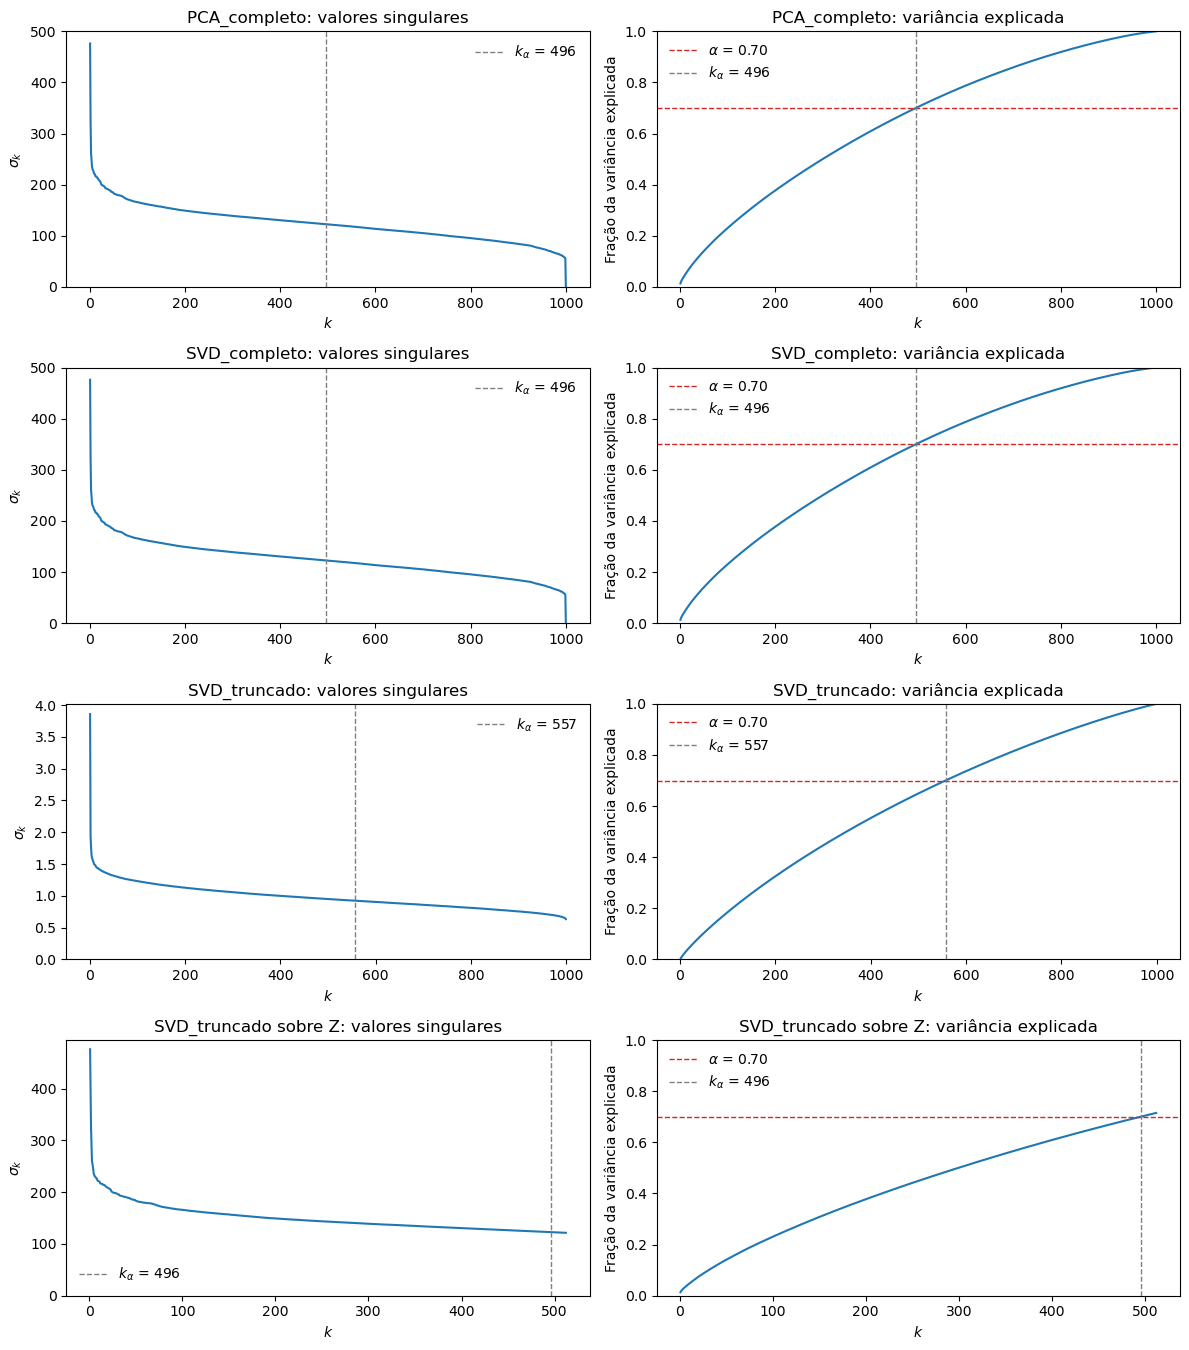

,k,"X_k (linhas, colunas)",σ calculados,||entrada||_F²,entrada
alpha = 0.7,,,,,
PCA_completo,496,"(1000, 496)",1000,16790000.0,"Z (densa, padronizada)"
SVD_completo,496,"(1000, 496)",1000,16790000.0,"Z (densa, padronizada)"
SVD_truncado,557,"(1000, 557)",999,1000.0,como passada (esparsa)
SVD_truncado sobre Z,496,"(1000, 496)",512,16790000.0,como passada (densa)


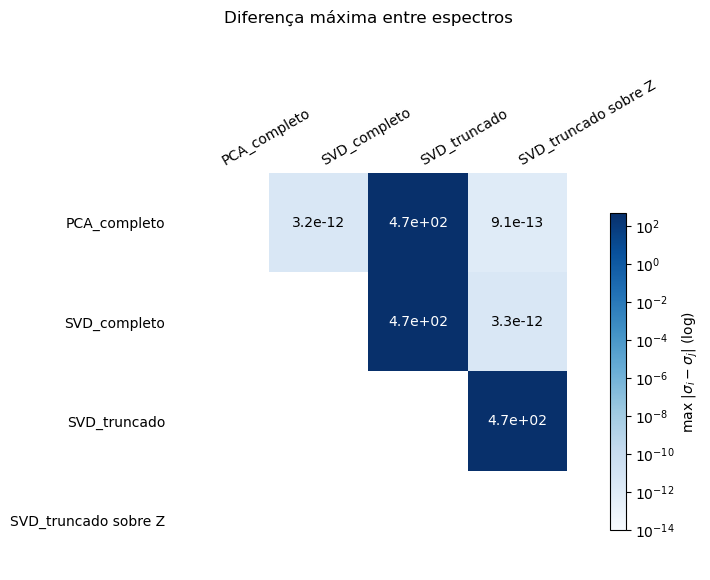

In [ ]:
verifica([PCA_completo, SVD_completo, SVD_truncado,
        ('SVD_truncado sobre Z', lambda X, a, info=None: SVD_truncado(padroniza(_como_matriz(X)[0]), a, info=info))],
       0.7);


Os resultados acima demonstram que o SVD truncado é um bom substituto para o SVD completo ou PCA, e confirma que os métodos escritos se comportam como esperado.

Primeiramente, o gráfico "Diferença máxima entre espectros" explicita que os métodos PCA, SVD completo e SVD truncado (aplicado sobre a matriz normalizada) trabalharam sobre a mesma matriz. Lê-se esse gráfico como "O valor numérico em cada célula é a diferença entre a matriz usada pelo método da linha $i$ e pelo método da coluna $j$ — dada pela diferença máxima entre os valores singulares de mesmo índice de cada matriz". Valores abaixo da diagonal principal são suprimidos, pois o gráfico é simétrico, e também na própria diagonal principal, porque compara matrizes identicas.

A célula (1,2) mostra que a matriz usada no PCA e a usada no SVD completo teve uma distância de aproximadamente zero (só não exatamente por erro de ponto flutuante). E da mesma forma, o método SVD truncado sobre Z utilizou a mesma matriz que PCA (1,4) e SVD completo (2,4). Mas, no caso do SVD truncado (aplicado sobre a matriz esparsa), fica claro que a matriz de entrada é diferente dos demais métodos, visto nas células (1,3), (2,3) e (3,4).

Essa diferença é reforçada analisando os gráficos $\sigma_k \times k$. Os três algoritimos produzem a mesma curva, mas o SVD truncado produz uma curva diferente. Mesmo assim, o $k$ encontrado é aproximadamente o mesmo. Dito isso, é seguro afirmar que o ferramental disponível na bibliteca `sklearn` está sendo usado corretamente pelos métodos implementados acima, e que a implementação do SVD truncado está se comportando como estudado.

In [ ]:
#@title Aplica o SVD truncado sobre X
reduz_dim = SVD_truncado

X_desc_k, k_desc = reduz_dim(X_desc, alpha=0.7)
print(f'X_desc {X_desc.shape} -> X_desc_k {X_desc_k.shape}, k = {k_desc}')

X_desc (1000, 16651) -> X_desc_k (1000, 561), k = 561


# Agrupamento

Como exploração inicial dos agrupamentos possíveis, pode-se utilizar o clustermap, feito a seguir.

Primeiramente, é escolhido o método de Ward como distância entre clusters. Em várias execuções do pipeline até esse ponto, com semente aleatória e tamanho 1000, o dendograma das colunas não revelou nenhuma informação, pois mostrou invariavelmente uma árvore de agrupamentos que aglomera pontos sequencialmente, sem grupos claros. Da mesma forma, o mapa de calor no centro mostrou ruído, sem agrupamentos claros.

/home/Leo/.conda/envs/python_dev-general/lib/python3.13/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/Leo/.conda/envs/python_dev-general/lib/python3.13/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


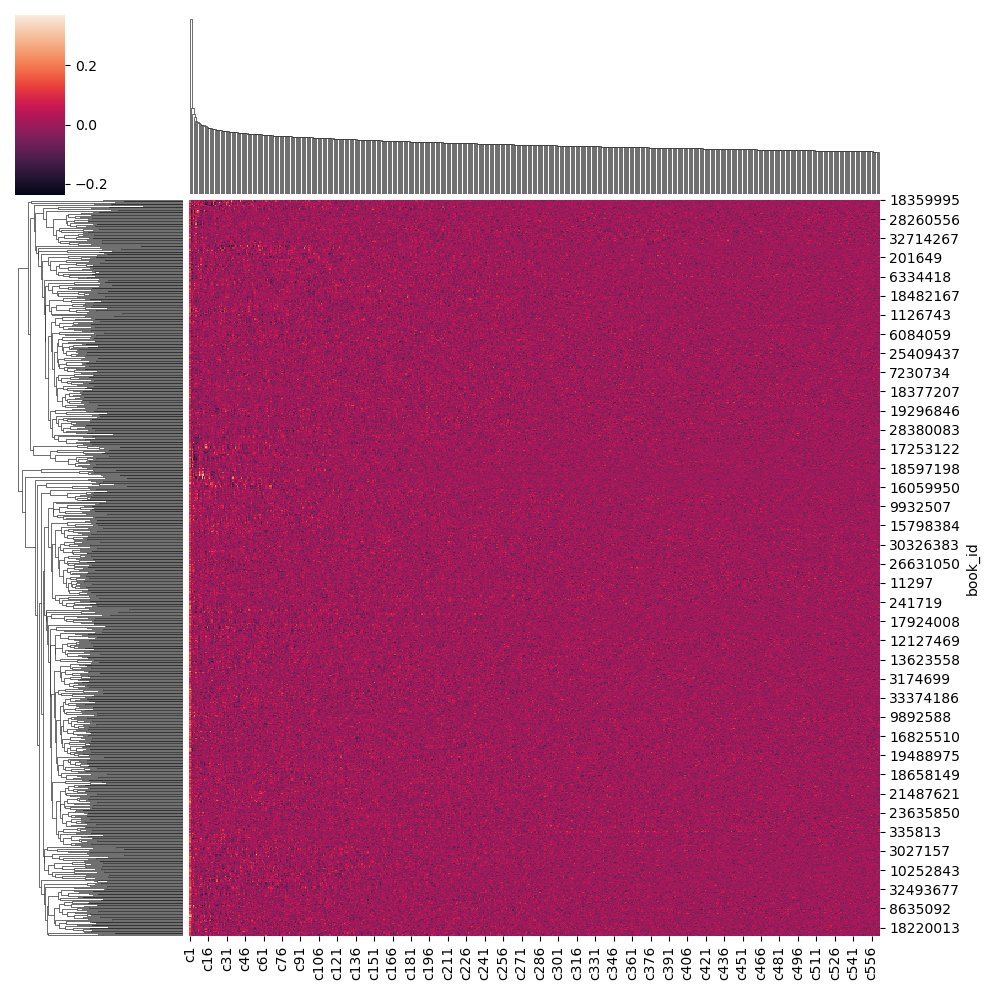

In [ ]:
#@title Comandos mínimos para repetir o pipeline até o clustermap
import seaborn as sns
semente = np.random.randint(0, 2**31)
df=livros.sample(n=1000, random_state=semente)
df.drop(inplace=True, columns=['idioma'])
reduz_dim = SVD_truncado
X_desc = calculaX(df['description'])

X_desc_k, k_desc = reduz_dim(X_desc, alpha=0.7)
sns.clustermap(data=X_desc_k, method='ward');


O dendograma das linhas resultou numa árvore que favorece agrupamentos. Na célula abaixo, é construído somente o dendograma das linhas, com um recurso interativo para selecionar uma distância de corte. Após muitas rodadas sucessivas, cada qual com uma semente diferente, verificou-se que um patamar de 1.6 produziu, consistentemente, grupos que "fazem sentido" (aproximadamente 20). Isto é, empiricamente, lembram uma distribuição de Paretto, com respeito ao número de membros em cada grupo, que é esperável quanto ao gênero de livros (alguns gêneros são mais frequentados por leitores, outros são de interesse mais estreito).

In [17]:
#@title Dendograma com corte interativo
import os, io, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from ipywidgets import FloatSlider, Image, VBox

# --- amostra e redução ---
semente = np.random.randint(0, 2**31)
df = livros.sample(n=1000, random_state=semente)
df.drop(inplace=True, columns=['idioma'])
reduz_dim = SVD_truncado
X_desc = calculaX(df['description'])
X_desc_k, k_desc = reduz_dim(X_desc, alpha=0.7)

# --- árvore ---
Z = linkage(X_desc_k, method='ward')
alturas = Z[:, 2]

# --- patamar lembrado: GitHub -> arquivo local -> metade da altura máxima ---
REPO_RAW = 'https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/'
ARQ_PATAMAR = 'patamar.json'

def le_patamar(padrao):
    try:
        return float(pd.read_json(REPO_RAW + ARQ_PATAMAR, typ='series')['patamar'])
    except Exception:
        pass
    if os.path.exists(ARQ_PATAMAR):
        return json.load(open(ARQ_PATAMAR))['patamar']
    return padrao

def salva_patamar(valor):
    json.dump({'patamar': float(valor)}, open(ARQ_PATAMAR, 'w'))

PATAMAR = globals().get('PATAMAR', le_patamar(float(alturas[-1] / 2)))

# --- figura como PNG, sem passar pelo widget Output ---
def figura_png(patamar):
    rot = fcluster(Z, t=patamar, criterion='distance')
    fig, ax = plt.subplots(figsize=(14, 5), dpi=100)
    dendrogram(Z, no_labels=True, color_threshold=patamar, ax=ax)
    ax.axhline(patamar, ls='--', color='red')
    ax.set_ylim(bottom=0)
    ax.set_xlabel('livros'); ax.set_ylabel('distância de Ward')
    ax.set_title(f'patamar = {patamar:.2f}  →  {rot.max()} grupos')
    buf = io.BytesIO()
    fig.savefig(buf, format='png', bbox_inches='tight')
    plt.close(fig)
    return buf.getvalue(), rot

# --- widget ---
img = Image(format='png', width=1100)
slider = FloatSlider(value=float(np.clip(PATAMAR, alturas.min(), alturas.max())),
                     min=alturas.min(), max=alturas.max(), step=0.01,
                     description='patamar', continuous_update=True)

def desenha(patamar):
    global PATAMAR, rotulos
    PATAMAR = patamar
    salva_patamar(patamar)
    png, rot = figura_png(patamar)
    img.value = png
    rotulos = pd.Series(rot, index=X_desc_k.index, name='grupo')

slider.observe(lambda ch: desenha(ch['new']), names='value')
desenha(slider.value)
display(VBox([slider, img]))

### Comparação entre métodos de agrupamento

Os agrupamentos são avaliados com medidas internas e externas. A medida interna selecionada é o coeficiente de silhueta ($SC$), e a medida externa é o *Adjusted Rand Index* ($ARI$). Optou-se por prosseguir dessa forma para alinhar a metodologia com o racional de aprendizado não supervisionado, proposto no trabalho — antes de avaliar o resultado de um agrupamento com o *ground truth*, ele precisa pelo menos "parecer bom". Foram analisados quatro métodos, em diferentes patamares de simplicidade: $k$-*means*, hierárquico, HDBSCAN e espectral.

- **Hierárquico:** Começando pelo hierárquico, ele foi escolhido para dar continuidade à análise exploratória, e foi parametrizado conforme aquele resultado: `distance_threshold=1.6`, `linkage='ward'`;
- **$k$-*means*:** Ainda aproveitando o resultado da exploração, verificou-se que foram produzidos aproximadamente 20 grupos, então o k-means foi parametrizado exatamente assim: `n_cluster=20`;
- **Espectral:** O n_clusters foi selecionado conforme o método `eigengap`;
- **HDBSCAN:** Foi verificado no desenvolvimento desse trabalho que o agrupamento hierárquico obteve resultados consistentes. Isso indicou que uma estratégia hierárquica, mas com critério de agrupamento mais "maleável", poderia alcançar resultados melhores do que uma baseada em distância, visto o problema de alta dimensionalidade imposto pela matriz TF-IDF. O HDBSCAN se enquadra nessa descrição. Os hiperparâmetros foram selecionados com base no guia de usuário do `sklearn` (https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html), levando em conta o desempenho em várias análises aleatorizadas, aproximando um `min_samples` que, na média, otimize o ARI.

In [ ]:
#@title Suite de agrupamento: silhueta, ARI e mapas gênero × grupo
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.patches import Circle
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import MultiLabelBinarizer

# --- medida externa: Rand ajustado sobre pares, com "correto" = pelo menos um gênero em comum ---
def _mesmo_grupo(rotulos):
    """Matriz n×n booleana: rotulos[i] == rotulos[j]."""
    r = np.asarray(rotulos)
    return r[:, None] == r[None, :]

def _compartilha_genero(generos):
    """generos: iterável de listas/conjuntos de gêneros, um por livro.
    Matriz n×n booleana: i e j têm pelo menos um gênero em comum."""
    B = MultiLabelBinarizer(sparse_output=True).fit_transform(generos)
    return (B @ B.T).toarray() > 0

def ari_pares(mesmo_real, mesmo_pred):
    """Índice de Rand ajustado (Hubert & Arabie, 1985) calculado sobre pares de objetos, a partir
    de duas relações binárias n×n ("mesmo par" no rótulo real e no agrupamento). Coincide com
    sklearn.metrics.adjusted_rand_score quando mesmo_real vem de uma partição; aqui mesmo_real
    pode vir de rótulos múltiplos (gêneros), caso em que não é uma partição."""
    iu = np.triu_indices(len(mesmo_real), 1)
    t, p = mesmo_real[iu], mesmo_pred[iu]
    N, T, P, a = len(t), t.sum(), p.sum(), (t & p).sum()
    esperado = T * P / N            # pares concordantes esperados ao acaso (permutação)
    maximo = (T + P) / 2
    return (a - esperado) / (maximo - esperado)

# --- medida interna: silhueta ---
def _plota_silhueta(ax, M, rotulos, metric, titulo, zoom):
    """Silhouette plot de um agrupamento, no formato do exemplo do scikit-learn usado em aula."""
    grupos = np.unique(rotulos)
    n_grupos = len(grupos)
    media = silhouette_score(M, rotulos, metric=metric)
    s_i = silhouette_samples(M, rotulos, metric=metric)

    x_min, x_max = media - zoom, media + zoom          # janela centrada na média

    y_lower = 10
    for j, g in enumerate(grupos):
        s_g = np.sort(s_i[rotulos == g])
        y_upper = y_lower + len(s_g)
        cor = cm.nipy_spectral(float(j) / n_grupos)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, s_g, facecolor=cor, edgecolor=cor, alpha=0.7)
        ax.text(x_min, y_lower + 0.5 * len(s_g), str(g), fontsize=8, va='center')
        y_lower = y_upper + 10

    ax.axvline(x=media, color='red', linestyle='--', label=f'SC médio = {media:.3f}')
    fora = int(((s_i < x_min) | (s_i > x_max)).sum())
    ax.set_xlim([x_min, x_max])
    if fora:
        ax.annotate(f'{fora} pontos fora da janela', xy=(0.99, 0.02), xycoords='axes fraction',
                    ha='right', fontsize=8, color='gray')
    ax.set_ylim([0, len(M) + (n_grupos + 1) * 10])
    ax.set_yticks([])
    ax.set_xlabel('coeficiente de silhueta $s_i$')
    ax.set_ylabel('grupo')
    ax.set_title(titulo)
    ax.legend(loc='upper right', frameon=False)
    return media

def avalia_agrupamentos(metodos, X, generos=None, metric='euclidean', ignora_ruido=True, zoom=0.1, plota=True):
    """Roda cada (metodo, params) sobre X, desenha o silhouette plot de cada um e resume os scores.
    generos: Series alinhada ao índice de X, com a lista de gêneros de cada livro; se dada, calcula
    o ARI por pares em que dois livros "deveriam" estar juntos se têm pelo menos um gênero em comum.
    Pontos com rótulo -1 (ruído) ficam fora da silhueta e do ARI se ignora_ruido=True.
    zoom é a meia-largura do eixo x em torno do SC médio. plota=False só calcula, sem figuras nem tabela.
    Devolve {nome: {'rotulos': Series, 'sc', 'ari', 'n_grupos', 'ruido', 'maior'}}."""
    M, idx = _como_matriz(X)
    M = _densa(M)
    G = None
    if generos is not None:
        g = pd.Series(generos).reindex(idx)
        if g.isna().any():
            raise ValueError(f'{int(g.isna().sum())} livros de X sem gênero em `generos`')
        G = _compartilha_genero(g)
    res = {}
    for metodo, params in metodos:
        nome = f"{metodo.__name__}({', '.join(f'{k}={v}' for k, v in params.items())})"
        rotulos = np.asarray(metodo(X, **params))
        serie = pd.Series(rotulos, index=idx, name='grupo')
        mascara = (rotulos != -1) if ignora_ruido else np.ones(len(rotulos), bool)
        ruido = int((~mascara).sum())
        n_grupos = len(np.unique(rotulos[mascara]))
        maior = int(serie[serie != -1].value_counts().max()) if (serie != -1).any() else 0
        ari = (ari_pares(G[np.ix_(mascara, mascara)], _mesmo_grupo(rotulos[mascara]))
               if G is not None and mascara.sum() > 1 else np.nan)
        silhueta_ok = 2 <= n_grupos <= mascara.sum() - 1
        sc = silhouette_score(M[mascara], rotulos[mascara], metric=metric) if silhueta_ok else np.nan
        res[nome] = dict(rotulos=serie, sc=sc, ari=ari, n_grupos=n_grupos, ruido=ruido, maior=maior)

        if plota:
            fig, ax = plt.subplots(figsize=(9, 5))
            linha2 = f'\nARI (≥ 1 gênero em comum) = {ari:.3f}' if G is not None else ''
            if not silhueta_ok:
                ax.set_title(f'{nome}: {n_grupos} grupo(s), silhueta indefinida' + linha2)
                ax.set_axis_off()
            else:
                titulo = f'{nome}: {n_grupos} grupos, SC = {sc:.3f}' + (f'  [ruído: {ruido}]' if ruido else '') + linha2
                _plota_silhueta(ax, M[mascara], rotulos[mascara], metric, titulo, zoom)
            fig.tight_layout()
            plt.show()

    if plota:
        resumo = pd.DataFrame({n: {'grupos': r['n_grupos'], 'ruído': r['ruido'], 'SC médio': round(r['sc'], 4),
                                   'ARI': round(r['ari'], 4), 'maior grupo': r['maior']}
                               for n, r in res.items()}).T
        resumo.index.name = f'métrica = {metric}'
        display(resumo)
    return res

# --- contagem de gêneros por grupo (base dos mapas) ---
def contagem_generos_por_grupo(rotulos, generos):
    """rotulos: Series grupo por book_id (ex.: resultado[nome]['rotulos']);
    generos: Series lista de gêneros por book_id. Cada gênero de cada livro é contado.
    Devolve DataFrame (gêneros únicos × grupos) com 'quantas vezes o gênero i apareceu no grupo j'."""
    pares = pd.DataFrame({'grupo': rotulos, 'genero': generos.reindex(rotulos.index)}).explode('genero').reset_index(drop=True)
    return pd.crosstab(pares['genero'], pares['grupo'])

# --- mapa Monte Carlo gênero × grupo: raio = frequência média no grupo, cor = dispersão entre rodadas ---
def frequencia_no_grupo(contagem):
    """contagem: DataFrame gêneros × grupos (contagem_generos_por_grupo). Devolve a frequência de cada gênero
    dentro do grupo, em % da maior contagem do grupo: 100 para o gênero mais frequente de cada coluna."""
    maximo = contagem.max(axis=0).replace(0, np.nan)
    return (100 * contagem / maximo).fillna(0)

def empilha_frequencias(contagens):
    """contagens: lista de DataFrames gêneros × grupos, um por rodada. Converte cada um em frequência no grupo
    (frequencia_no_grupo), alinha pela união de gêneros e de grupos e devolve (media, desvio, presenca):
    média e desvio padrão (ddof=1) da frequência entre as rodadas em que o grupo existiu, e
    presenca = em quantas rodadas cada grupo existiu."""
    generos = sorted(set().union(*(c.index for c in contagens)))
    grupos = sorted(set().union(*(c.columns for c in contagens)))
    pilha = np.stack([frequencia_no_grupo(c.reindex(index=generos, fill_value=0))
                      .reindex(columns=grupos).to_numpy(dtype=float) for c in contagens])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)      # grupo visto em 1 rodada só: σ = NaN
        media = pd.DataFrame(np.nanmean(pilha, axis=0), index=generos, columns=grupos)
        desvio = pd.DataFrame(np.nanstd(pilha, axis=0, ddof=1), index=generos, columns=grupos)
    presenca = pd.Series(np.isfinite(pilha[:, 0, :]).sum(axis=0), index=grupos)
    return media, desvio, presenca

def mapa_generos_grupos_mc(contagens, titulo='', cores=('#006c00', '#dfdfdf'), celula=0.45, raio_max=0.47,
                           cor_grade='#d0d0d0'):
    """Cada célula (gênero, grupo) tem fundo branco e um círculo centrado, sem transparência:
    raio = média entre rodadas da frequência do gênero no grupo (% da maior contagem do grupo):
           0 % -> raio 0; 100 % -> raio_max (em unidades de célula; 0.5 toca a borda);
    cor  = desvio padrão dessa frequência entre rodadas, em pontos percentuais, numa escala de
           cores[0] (σ = 0) a cores[1] (σ máximo observado). cores: 2+ cores ou um nome de colormap.
           Grupo presente numa única rodada tem σ indefinido e sai como círculo vazado.
    Devolve (media, desvio) da frequência, DataFrames gêneros × grupos."""
    media, desvio, presenca = empilha_frequencias(contagens)
    n_gen, n_grp = media.shape; n_rod = len(contagens)
    s_max = float(np.nanmax(desvio.to_numpy())) if np.isfinite(desvio.to_numpy()).any() else 0.0
    norma = Normalize(vmin=0, vmax=s_max if s_max > 0 else 1)
    escala = plt.get_cmap(cores) if isinstance(cores, str) else LinearSegmentedColormap.from_list('dispersao', list(cores))
    fig, ax = plt.subplots(figsize=(celula * n_grp + 3.2, celula * n_gen + 1.6))
    ax.set_facecolor('white')
    for i in range(n_gen):
        for j in range(n_grp):
            m = media.iat[i, j]
            if np.isnan(m) or m <= 0:
                continue
            s = desvio.iat[i, j]
            if np.isfinite(s):          # círculo cheio: cor = σ
                ax.add_patch(Circle((j, i), radius=raio_max * m / 100, facecolor=escala(norma(s)), edgecolor='none'))
            else:                       # σ indefinido (grupo presente em 1 rodada): círculo vazado
                ax.add_patch(Circle((j, i), radius=raio_max * m / 100, facecolor='none', edgecolor='#808080', linewidth=0.8))
    ax.set_xlim(-0.5, n_grp - 0.5); ax.set_ylim(n_gen - 0.5, -0.5); ax.set_aspect('equal')
    ax.set_xticks(range(n_grp), [str(g) for g in media.columns]); ax.set_yticks(range(n_gen), media.index)
    ax.set_xticks(np.arange(-0.5, n_grp), minor=True); ax.set_yticks(np.arange(-0.5, n_gen), minor=True)
    ax.grid(which='minor', color=cor_grade, linewidth=0.6); ax.tick_params(which='minor', length=0)
    ax.tick_params(axis='both', labelsize=8)
    ax.set_xlabel('grupo calculado'); ax.set_ylabel('gênero')
    if (presenca < n_rod).any():
        for j, p in enumerate(presenca):
            if p < n_rod: ax.text(j, -0.6, f'{p}/{n_rod}', ha='center', va='bottom', fontsize=5, color='gray')
    fig.colorbar(ScalarMappable(norm=norma, cmap=escala), ax=ax, shrink=0.8,
                 label=f'σ da frequência entre {n_rod} rodadas (pontos percentuais)')
    ax.set_title((titulo + '\n' if titulo else '') + 'raio = frequência média do gênero no grupo (% da maior contagem do grupo)\n'
                 f'cor = σ da frequência entre rodadas (máx = {s_max:.1f} p.p.); vazado = σ indefinido', fontsize=9)
    fig.tight_layout(); plt.show()
    return media, desvio

# --- alinhamento de rótulos entre rodadas (método húngaro) ---
def alinha_grupos(rotulos, contagens, criterio='generos', metrica='cosine', limiar=None):
    """Renomeia os grupos de cada rodada para que o 'mesmo' grupo tenha o mesmo rótulo em todas as rodadas,
    casando cada rodada com uma referência acumulada pelo método húngaro (scipy.optimize.linear_sum_assignment).

    rotulos:   lista de Series (grupo por book_id), uma por rodada (res[nome]['rotulos']).
    contagens: lista de DataFrames gêneros × grupos, uma por rodada (contagem_generos_por_grupo).
    criterio:  'generos' -> custo = distância `metrica` (scipy cdist) entre o perfil de gêneros do grupo
                            (coluna da matriz de contagem) e o perfil médio de cada grupo da referência;
               'livros'  -> custo = -(número de livros em comum) entre o grupo e cada grupo da referência,
                            contando só livros que apareceram em ambas as rodadas.
    limiar:    custo máximo para aceitar um par ('generos'); None = aceita qualquer par atribuído.
               Em 'livros', par sem nenhum livro em comum nunca é aceito.
    Grupo sem par aceito recebe um rótulo novo e passa a fazer parte da referência. Ruído (-1) nunca é renomeado.
    Referência: começa na rodada 0; em 'generos' o perfil de cada rótulo é a média dos perfis já casados a ele;
    em 'livros' é o rótulo acumulado por livro (a primeira ocorrência de cada livro prevalece).
    Devolve (rotulos_alinhados, contagens_alinhadas, mapas); mapas[r] = {rótulo original: rótulo alinhado}."""
    generos = sorted(set().union(*(c.index for c in contagens)))
    perfis = [c.reindex(index=generos).fillna(0).astype(float) for c in contagens]
    ref_perfil, ref_n = {}, {}                   # rótulo -> perfil médio, nº de perfis acumulados
    ref_livros = pd.Series(dtype='int64')        # book_id -> rótulo acumulado
    proximo = 0
    rot_al, cont_al, mapas = [], [], []
    for serie, perfil, contagem in zip(rotulos, perfis, contagens):
        grupos = [g for g in perfil.columns if g != -1]
        mapa = {-1: -1}
        ref_rot = sorted(ref_perfil) if criterio == 'generos' else sorted(set(ref_livros.unique()) - {-1})
        pendentes = list(grupos)
        if ref_rot and grupos:
            if criterio == 'generos':
                R = np.stack([ref_perfil[r] for r in ref_rot])
                C = perfil[grupos].to_numpy().T
                custo = np.nan_to_num(cdist(R, C, metric=metrica), nan=np.inf, posinf=np.inf)
                aceita = lambda c: np.isfinite(c) and (limiar is None or c <= limiar)
            else:
                comum = serie.index.intersection(ref_livros.index)
                tabela = pd.crosstab(ref_livros.loc[comum], serie.loc[comum]).reindex(index=ref_rot, columns=grupos, fill_value=0)
                custo = -tabela.to_numpy(dtype=float)
                aceita = lambda c: c < 0
            custo_fin = np.where(np.isfinite(custo), custo, np.nanmax(custo[np.isfinite(custo)], initial=0) + 1)
            for i, j in zip(*linear_sum_assignment(custo_fin)):
                if aceita(custo[i, j]):
                    mapa[grupos[j]] = int(ref_rot[i])
                    pendentes.remove(grupos[j])
        for g in pendentes:                      # grupos sem par: rótulo novo
            mapa[g] = proximo; proximo += 1
        proximo = max(proximo, max(mapa.values(), default=-1) + 1)
        # atualiza a referência
        for g in grupos:
            r = mapa[g]
            if criterio == 'generos':
                p = perfil[g].to_numpy()
                n = ref_n.get(r, 0)
                ref_perfil[r] = (ref_perfil[r] * n + p) / (n + 1) if n else p
                ref_n[r] = n + 1
        novo = serie.map(mapa)
        if criterio == 'livros':
            novos = novo.index.difference(ref_livros.index)
            ref_livros = pd.concat([ref_livros, novo.loc[novos]])
        rot_al.append(novo.rename(serie.name))
        c = contagem.rename(columns=mapa)
        cont_al.append(c[sorted(c.columns)])
        mapas.append(mapa)
    return rot_al, cont_al, mapas


In [ ]:
#@title Métodos de agrupamento: metodo(X, **params) -> rotulos
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering, HDBSCAN

def kmeans(X, **params):
    """k-means. params: n_clusters, n_init, random_state, ..."""
    M, _ = _como_matriz(X)
    return KMeans(**params).fit_predict(_densa(M))

def hierarquico(X, **params):
    """Aglomerativo. params: linkage, e n_clusters ou distance_threshold (com n_clusters=None)."""
    M, _ = _como_matriz(X)
    return AgglomerativeClustering(**params).fit_predict(_densa(M))

def espectral(X, **params):
    """Espectral. params: n_clusters, affinity ('nearest_neighbors' | 'rbf'), n_neighbors, random_state, ..."""
    M, _ = _como_matriz(X)
    return SpectralClustering(**params).fit_predict(_densa(M))

def hdbscan(X, **params):
    """HDBSCAN. params: min_cluster_size, min_samples, metric, ... Rótulo -1 = ruído."""
    M, _ = _como_matriz(X)
    return HDBSCAN(**params).fit_predict(_densa(M))


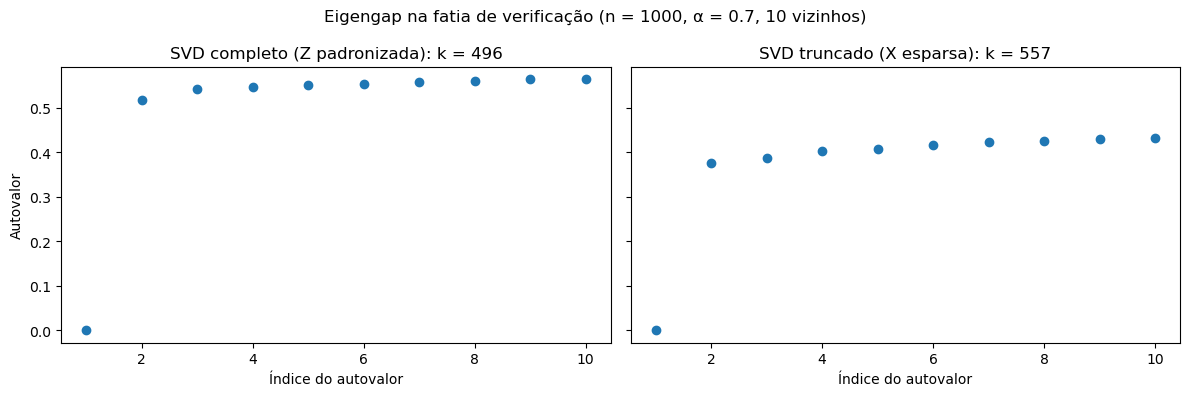

In [ ]:
#@title Eigengap: SVD completo vs. SVD truncado sobre a fatia de verificação
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import kneighbors_graph
from scipy.sparse import csgraph
from numpy import linalg as LA

ALPHA_EG = 0.7        # mesma fração de variância usada no dendograma
N_VIZINHOS = 10       # deve coincidir com n_neighbors da chamada do espectral
N_VALORES = 10        # quantos autovalores mostrar

# --- pipeline enxuto sobre a fatia fixa (SEMENTE_VER, N_VER) ---
DF_VER = carrega_fatia()
X_VER = calculaX(DF_VER['description'])
reducoes = {
    'SVD completo (Z padronizada)': SVD_completo(X_VER, ALPHA_EG),
    'SVD truncado (X esparsa)':     SVD_truncado(X_VER, ALPHA_EG),
}

# --- eigengap, como no material de aula (grafo kNN simetrizado + Laplaciana normalizada) ---
def autovalores_laplaciana(X, n_neighbors=N_VIZINHOS):
    G = kneighbors_graph(np.asarray(X), n_neighbors=n_neighbors, include_self=True)
    A = 0.5 * (G + G.T)
    L = csgraph.laplacian(A, normed=True).todense()
    valores, _ = LA.eigh(L)             # já em ordem crescente
    return valores

fig, axes = plt.subplots(1, len(reducoes), figsize=(6 * len(reducoes), 4), sharey=True)
for ax, (rotulo, (Xk, k)) in zip(axes, reducoes.items()):
    valores = autovalores_laplaciana(Xk)[:N_VALORES]
    ax.scatter(np.arange(1, N_VALORES + 1), valores)
    ax.set_xlabel('Índice do autovalor')
    ax.set_title(f'{rotulo}: k = {k}')
axes[0].set_ylabel('Autovalor')
fig.suptitle(f'Eigengap na fatia de verificação (n = {len(DF_VER)}, α = {ALPHA_EG}, {N_VIZINHOS} vizinhos)')
fig.tight_layout()
plt.show()


In [ ]:
#@title Suite de seleção de parâmetro por simulação Monte Carlo: curva SC × parâmetro
import io
import contextlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- estilo (plot_mc.py + layout_one-column / base_IEEE-TIM-2026) ---
ESTILO = dict(
    figsize=(6.4, 4.8),
    label_fontsize=10, title_fontsize=12, annotate_fontsize=8, legend_fontsize=7, tick_label_fontsize=6,
    linewidth_medium=1, spine_linewidth=0.5, region_alpha=0.45, cor='C1', plotarea_facecolor='#fbfbfb',
    grid_options=[dict(which='major', color='#e0e0e0', linewidth=0.6),
                  dict(which='minor', color='#f0f0f0', linewidth=0.3, linestyle='--')],
    title_prefix='Simulação Monte Carlo',
)

def varre_parametro(metodo, params_fixos, parametro, valores, n_rodadas=10, n=1000, alpha=0.7, estilo=ESTILO):
    """Para cada rodada: nova amostra aleatória -> TF-IDF -> SVD truncado; roda `metodo` com
    `params_fixos` e cada valor de `parametro`, guardando a silhueta média por valor.
    `parametro` é um nome ('n_clusters') ou uma tupla de nomes que recebem o mesmo valor
    (('min_cluster_size', 'min_samples')).
    Devolve DataFrame (rodadas × valores), com a semente de cada rodada no índice, e desenha
    média e envelope mín–máx entre rodadas no estilo de plot_mc.py."""
    nomes = (parametro,) if isinstance(parametro, str) else tuple(parametro)
    rotulo_param = ' = '.join(nomes)
    valores = list(dict.fromkeys(valores))                       # remove repetidos, preserva a ordem
    if len(valores) < 2:
        raise ValueError(f'`valores` precisa de pelo menos 2 valores distintos; recebeu {valores}')
    metodos = [(metodo, params_fixos | {nm: v for nm in nomes}) for v in valores]
    tabela = {}
    with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
        warnings.simplefilter('ignore')
        for _ in range(n_rodadas):
            semente = np.random.randint(0, 2**31)
            df = livros.sample(n=n, random_state=semente).drop(columns=['idioma'])
            X_desc_k, _ = SVD_truncado(calculaX(df['description']), alpha=alpha)
            res = avalia_agrupamentos(metodos, X_desc_k, plota=False)
            tabela[semente] = [r['sc'] for r in res.values()]
    resultados = pd.DataFrame.from_dict(tabela, orient='index', columns=valores)
    resultados.index.name = 'semente'
    resultados.columns.name = rotulo_param

    # --- estatísticas MC (como em plot_mc.py: envelope mín/máx e média) ---
    inferior, media, superior = resultados.min(), resultados.mean(), resultados.max()
    desvio = resultados.std(ddof=1)
    i_ref = media.idxmax()                                       # troque por idxmin se preferir o mínimo

    # --- figura ---
    fig, ax = plt.subplots(1, figsize=estilo['figsize'])
    ax.plot(valores, media, color=estilo['cor'], linewidth=estilo['linewidth_medium'],
            marker='o', markersize=2.5, label=f'média de {n_rodadas} rodadas', zorder=4)
    ax.fill_between(valores, inferior, superior, color=estilo['cor'], alpha=estilo['region_alpha'],
                    linewidth=0, label='envelope mín–máx', zorder=3)
    ax.annotate(rf'SC = {media[i_ref]:.4f} $\pm$ {desvio[i_ref]:.4f} em {rotulo_param} = {i_ref}',
                xy=(0.99, 0.04), xycoords='axes fraction', fontsize=estilo['annotate_fontsize'],
                horizontalalignment='right', verticalalignment='bottom', zorder=5)
    ax.set_facecolor(estilo['plotarea_facecolor'])
    ax.minorticks_on()
    for opcao in estilo['grid_options']:
        ax.grid(**opcao)
    ax.set_xlabel(rotulo_param, fontsize=estilo['label_fontsize'])
    ax.set_ylabel('SC médio', fontsize=estilo['label_fontsize'])
    ax.legend(fontsize=estilo['legend_fontsize'])
    ax.tick_params(axis='both', labelsize=estilo['tick_label_fontsize'])
    for spine in ax.spines.values():
        spine.set_linewidth(estilo['spine_linewidth'])
    fixos = ', '.join(f'{k}={v}' for k, v in params_fixos.items())
    ax.set_title(f"{estilo['title_prefix']}\n{metodo.__name__}({fixos}), n = {n}, α = {alpha}",
                 fontsize=estilo['title_fontsize'])
    plt.show()
    return resultados


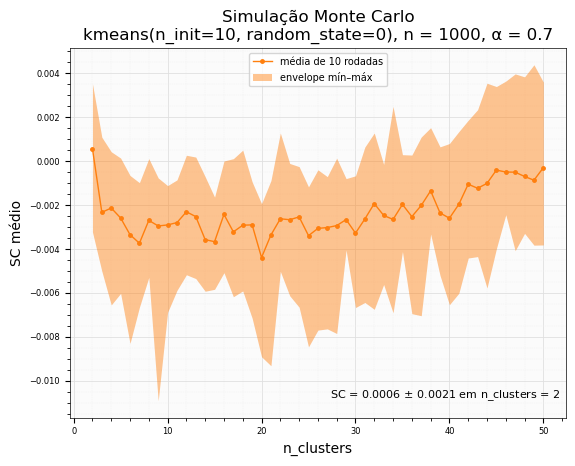

In [ ]:
#@title Simulação MC k-means (n_clusters)
mc_kmeans = varre_parametro(kmeans, dict(n_init=10, random_state=0),
                            'n_clusters', range(1, 51), n_rodadas=10)


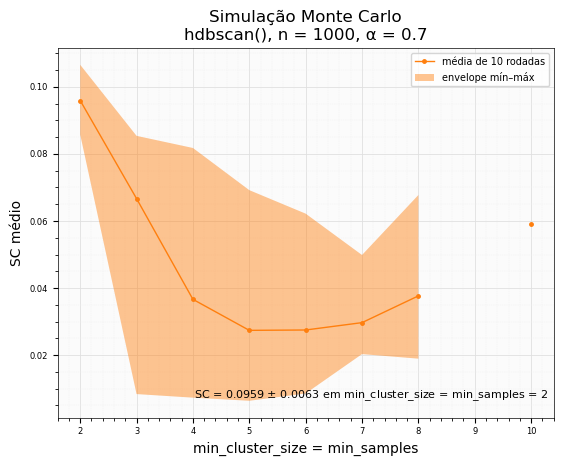

In [ ]:
#@title Simulação MC HDBSCAN (min_cluster_size=min_samples)
mc_hdbscan = varre_parametro(hdbscan, dict(),
                            ('min_cluster_size', 'min_samples'), range(2, 50), n_rodadas=10)


semente = 458595297
X_desc (1000, 16936) -> X_desc_k (1000, 561), k = 561


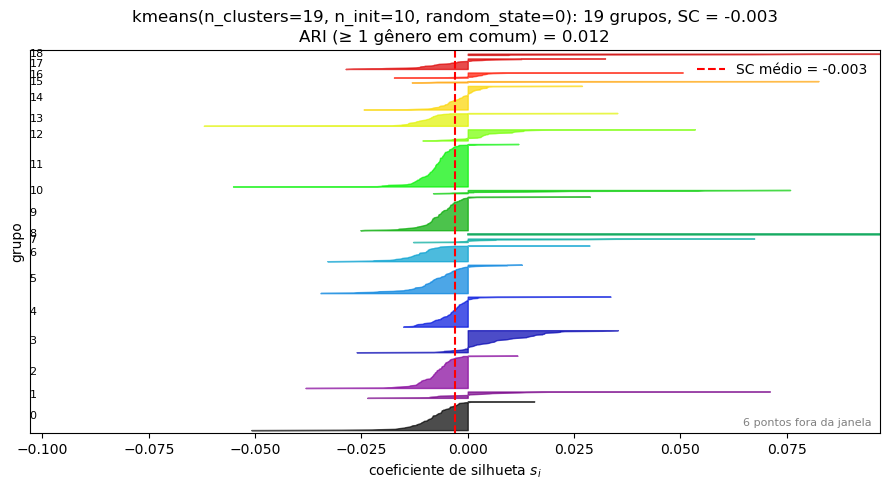

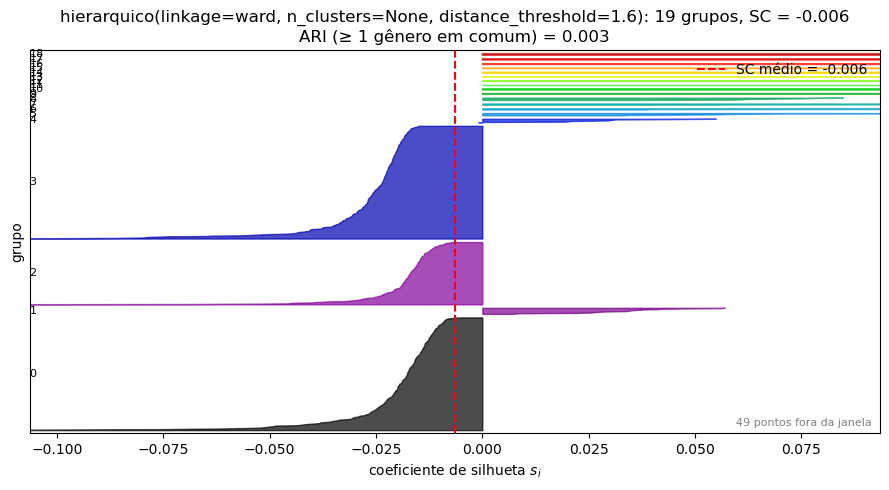

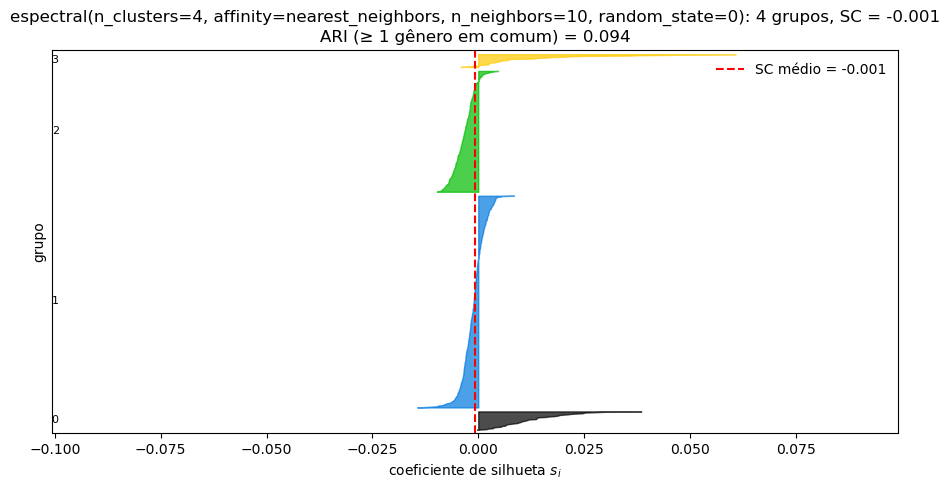

/home/Leo/.conda/envs/python_dev-general/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


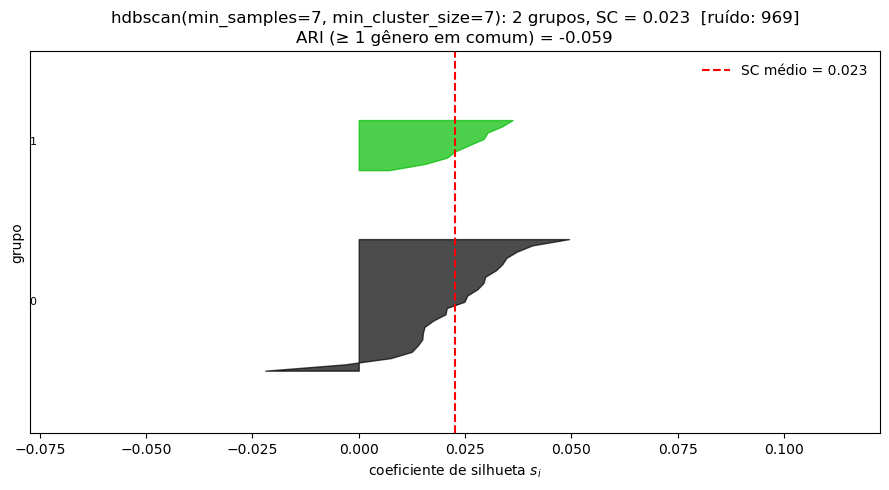

,grupos,ruído,SC médio,ARI,maior grupo
métrica = euclidean,,,,,
"kmeans(n_clusters=19, n_init=10, random_state=0)",19.0,0.0,-0.0030,0.0118,134.0
"hierarquico(linkage=ward, n_clusters=None, distance_threshold=1.6)",19.0,0.0,-0.0065,0.0032,354.0
"espectral(n_clusters=4, affinity=nearest_neighbors, n_neighbors=10, random_state=0)",4.0,0.0,-0.0008,0.0941,581.0
"hdbscan(min_samples=7, min_cluster_size=7)",2.0,969.0,0.0226,-0.0592,22.0


In [ ]:
#@title Aplica o suite de agrupamento sobre uma amostra aleatória
import numpy as np

# --- pipeline enxuto: amostra -> TF-IDF -> redução ---
semente = np.random.randint(0, 2**31)
print(f'semente = {semente}')
df = livros.sample(n=1000, random_state=semente)
df.drop(inplace=True, columns=['idioma'])
reduz_dim = SVD_truncado
X_desc = calculaX(df['description'])
X_desc_k, k_desc = reduz_dim(X_desc, alpha=0.7)
print(f'X_desc {X_desc.shape} -> X_desc_k {X_desc_k.shape}, k = {k_desc}')

# --- rótulo real: lista de gêneros de cada livro, mesmo índice de X_desc_k ---
generos = df['genre'].str.split('|').apply(lambda g: [x.strip() for x in g])

resultado = avalia_agrupamentos([
    (kmeans,      dict(n_clusters=19, n_init=10, random_state=0)),
    (hierarquico, dict(linkage='ward', n_clusters=None, distance_threshold=1.6)),
    (espectral,   dict(n_clusters=4, affinity='nearest_neighbors', n_neighbors=10, random_state=0)),
    (hdbscan,     dict(min_samples=(min_samples:=7),min_cluster_size=min_samples)),
], X_desc_k, generos=generos)

,grupos,ruído,SC médio,ARI,maior grupo
μ ± σ em 50 rodadas,,,,,
"kmeans(n_clusters=19, n_init=10, random_state=0)",19.0000 ± 0.0000,0.0000 ± 0.0000,-0.0034 ± 0.0029,0.0102 ± 0.0097,222.6200 ± 89.7568
"hierarquico(linkage=ward, n_clusters=None, distance_threshold=1.6)",19.5200 ± 3.4478,0.0000 ± 0.0000,-0.0090 ± 0.0049,0.0237 ± 0.0139,472.0600 ± 113.6729
"espectral(n_clusters=4, affinity=nearest_neighbors, n_neighbors=10, random_state=0)",4.0000 ± 0.0000,0.0000 ± 0.0000,-0.0003 ± 0.0021,0.0402 ± 0.0174,482.7800 ± 76.2614
"hdbscan(min_samples=7, min_cluster_size=7)",1.5000 ± 0.9742,973.6000 ± 21.7162,0.0373 ± 0.0175,0.0793 ± 0.0905,18.4000 ± 18.2287


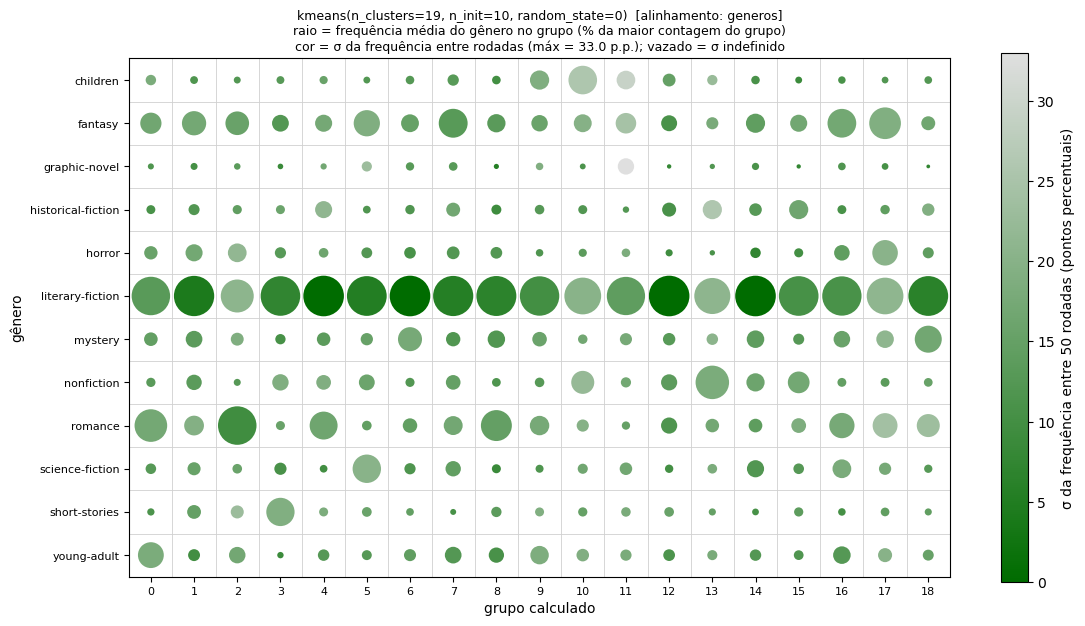

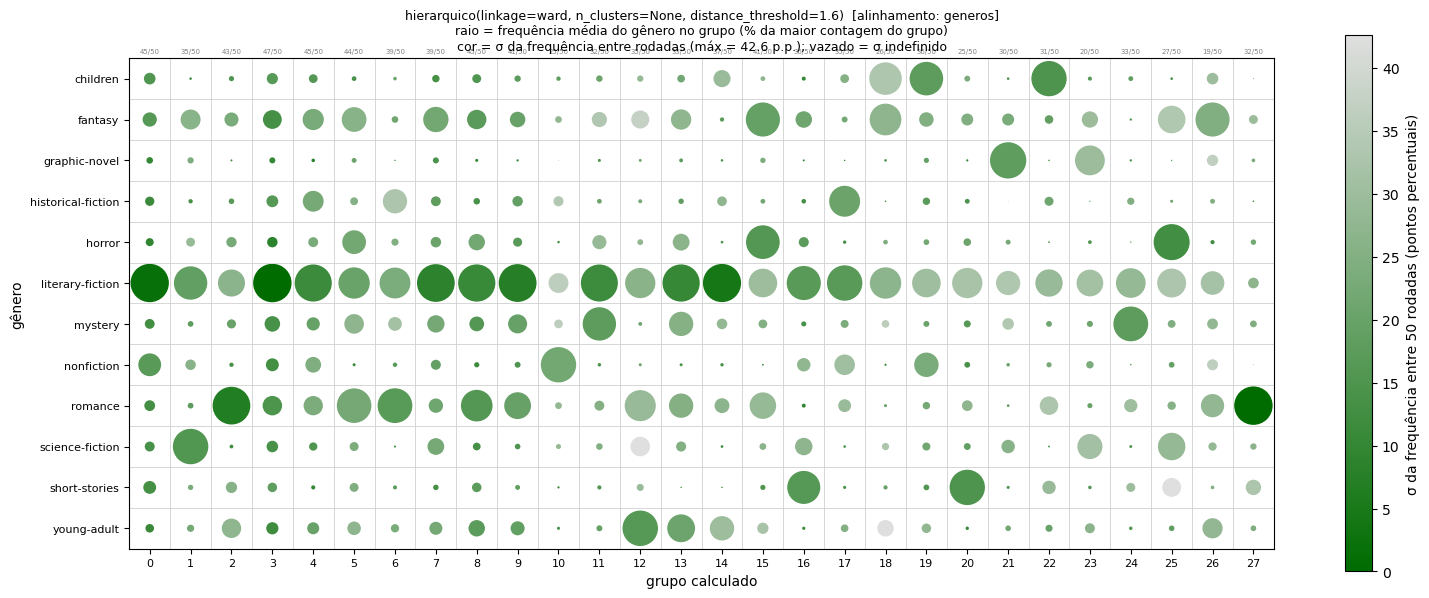

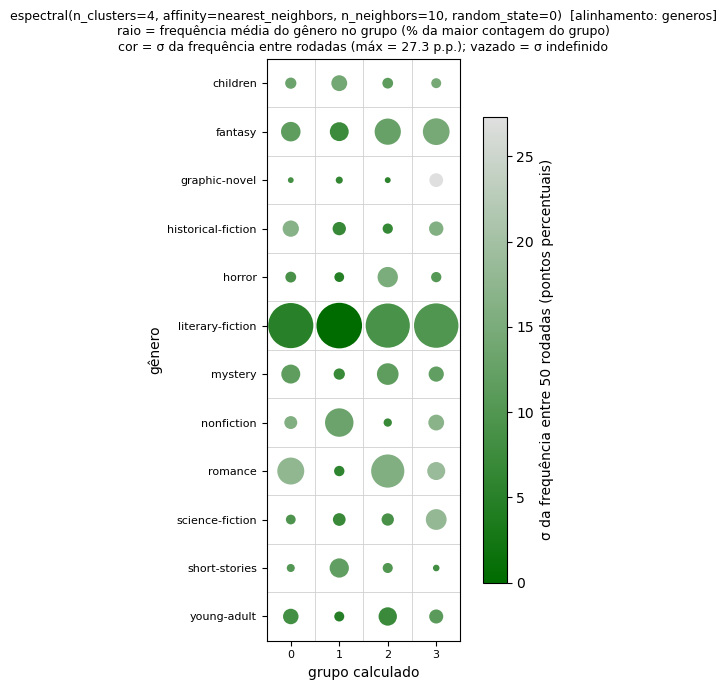

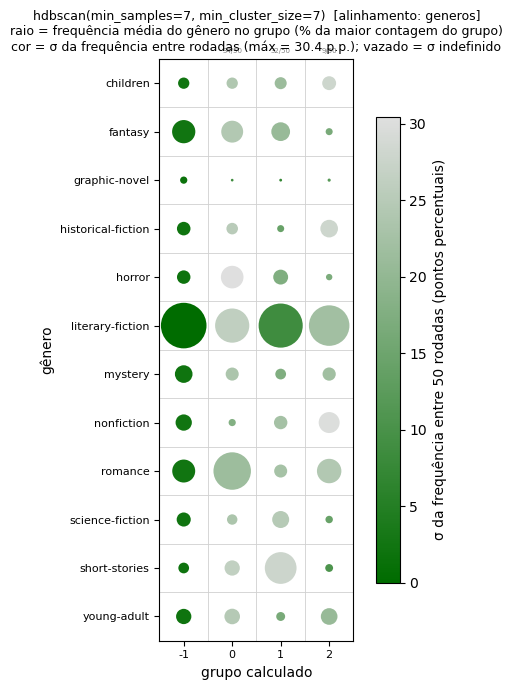

In [ ]:
#@title Repete o suite de agrupamento N vezes, com amostras aleatórias, e resume
import io
import contextlib
import warnings
import numpy as np
import pandas as pd

N_RODADAS = 50
CRITERIO = 'generos'     # alinhamento dos grupos entre rodadas: 'livros' ou 'generos' (ver alinha_grupos)
METODOS = [
    (kmeans,      dict(n_clusters=19, n_init=10, random_state=0)),
    (hierarquico, dict(linkage='ward', n_clusters=None, distance_threshold=1.6)),
    (espectral,   dict(n_clusters=4, affinity='nearest_neighbors', n_neighbors=10, random_state=0)),
    (hdbscan,     dict(min_samples=(min_samples:=7),min_cluster_size=min_samples)),
]
COLUNAS = {'grupos': 'n_grupos', 'ruído': 'ruido', 'SC médio': 'sc', 'ARI': 'ari', 'maior grupo': 'maior'}

rodadas = {}          # nome do método -> {coluna: [valor por rodada]}
rotulos = {}          # nome do método -> [Series grupo por book_id, por rodada]
contagens = {}        # nome do método -> [matriz gêneros × grupos por rodada]
sementes = []
with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
    warnings.simplefilter('ignore')
    for i in range(N_RODADAS):
        # --- pipeline enxuto: amostra -> TF-IDF -> redução ---
        semente = np.random.randint(0, 2**31)
        sementes.append(semente)
        df = livros.sample(n=1000, random_state=semente)
        df.drop(inplace=True, columns=['idioma'])
        X_desc = calculaX(df['description'])
        X_desc_k, k_desc = SVD_truncado(X_desc, alpha=0.7)
        generos = df['genre'].str.split('|').apply(lambda g: [x.strip() for x in g])

        res = avalia_agrupamentos(METODOS, X_desc_k, generos=generos, plota=False)
        for nome, r in res.items():
            linha = rodadas.setdefault(nome, {c: [] for c in COLUNAS})
            for coluna, chave in COLUNAS.items():
                linha[coluna].append(r[chave])
            rotulos.setdefault(nome, []).append(r['rotulos'])
            contagens.setdefault(nome, []).append(contagem_generos_por_grupo(r['rotulos'], generos))

# --- 1º DataFrame: cada célula é a lista dos resultados por rodada ---
experimentos = pd.DataFrame(rodadas).T
experimentos.insert(0, 'semente', [list(sementes)] * len(experimentos))
experimentos.index.name = f'{N_RODADAS} rodadas'
# display(experimentos)

# --- 2º DataFrame: média ± desvio padrão (amostral, ddof=1) de cada célula, exceto a semente ---
def mu_sigma(valores):
    v = np.asarray(valores, dtype=float)
    v = v[np.isfinite(v)]                       # rodadas com medida indefinida (NaN) ficam de fora
    if len(v) == 0:
        return 'nan'
    sigma = np.std(v, ddof=1) if len(v) > 1 else np.nan
    return f'{np.mean(v):.4f} ± {sigma:.4f}'

estatisticas = experimentos.drop(columns='semente').map(mu_sigma)
estatisticas.index.name = f'μ ± σ em {N_RODADAS} rodadas'
display(estatisticas)

# --- alinha os rótulos entre rodadas (método húngaro) e desenha um mapa MC por método ---
alinhados = {nome: alinha_grupos(rotulos[nome], contagens[nome], criterio=CRITERIO) for nome in contagens}
mapas = {nome: mapa_generos_grupos_mc(cont_al, titulo=f'{nome}  [alinhamento: {CRITERIO}]')
         for nome, (rot_al, cont_al, _) in alinhados.items()}


# Resultados

Após iterar sobre os procedimentos descritos acima, são reunidos os resultados mais importantes. De modo geral, pode-se afirmar que foi encontrado uma relação sutil entre a descrição e o gênero do livro.

## Validação

>1.i Como foi escolhido o número de componentes principais para o PCA?

Foi demonstrado que o critério de seleção do número de componentes principais está conforme o estudado no decorrer da disciplina. A metodologia foi retirada diretamente do livro-referência (https://dataminingbook.info/book_html/), e baseia-se na lógica de determinar como hiperparametro a fração da variância explicada, $\alpha$, e calcular o número de componentes $k$ a partir dele. Para o método de redução de dimensionalidade selecionado, SVD truncado, foi usado o procedimento de cálculo da variância explicada implementado na biblioteca `sklearn`.

>1.ii O número de componentes principais tem um impacto significativo nos resultados?

Sim. Conforme visto na comparação entre os resultados da redução por cada método, no caso específico desse conjunto de dados, a curva [variância explicada] $\times$ [$k$] cresce, a grosso modo, linearmente. Isso significa que não há um $k$, a partir do qual a variância explicada salte rapidamente para um patamar alto, logo não há um número de componentes principais "preferencial". Soma-se a isso o fato de a redução de dimensionalidade ser uma operação com perda de informação (da informação embutida no conjunto de dados, que potencialmente exprime a relação procurada, descrição → gênero), e fica evidente que a escolha do $\alpha$ é crítica. Tentar ser excessivamente econômico com a escolha de $\alpha$ implica em eliminar boa parte do sinal procurado.

>1.iii É necessário usar PCA neste trabalho?

Por motivos práticos, é necessário usar algum algoritimo de redução de dimensionalidade. O conjunto de dados é proibitivamente grande para um tratamento completo em tempo razoável. Conforme visto na verificação de PCA, a curva [variância explicada] $\times$ [$k$] do PCA é idêntica ao do SVD completo, que por sua vez é quase idêntica à do SVD truncado. O SVD truncado é útil aqui, pois permite trabalhar com matrizes esparsas. Isso torna trabalhar com conjuntos de dados grandes mais econômico, que se reverte na possibilidade de escolher $\alpha$ maior, em comparação a um método que trabalhe só sobre matrizes densas, para aproximadamente o mesmo tempo de processamento.


>2.i Como o número de grupos para cada algoritmo de agrupamento foi definido?

O número de agrupamentos pelo método hierárquico foi definido em função da distância de corte. Procurou-se um patamar que, em várias rodadas sucessivas sobre uma fatia de tamanho fixo mas aleatorizada, produziu (i) um número de grupos "razoável", de poucas dezenas; e (ii) grupos com tamanhos que, empiricamente, durante a exploração, pareçam demonstrar uma distribuição de Paretto. Esse patamar foi 1.6, e produziu aproximadamente 20 grupos. O número de grupos para o $k$-*means* foi por simulação Monte Carlo [SC] $\times$ [n_clusters], de modo a escolher o `n_clusters` que maximiza o coeficiente de silhueta. O número de grupos do agrupamento espectral foi definido pelo método *eigengap*, e do HDBSCAN foi definido também por simulação Monte Carlo, mas sobre o hiperparâmetro `min_cluster_size=min_samples`, de modo a maximizar o `SC`.

>2.ii A escolha do algoritmo de agrupamento impacta significativamente os resultados? E o número de grupos?

Sim. Cada algoritimo analisado produziu um agrupamento com SC e ARI diferentes, e mudar o número de grupos também.

## Análise


Para visualizar a correspondência entre os grupos formados e os gêneros reais, foi concebido um gráfico como descrito abaixo, que se assemelha a um histograma. Para cada grupo resultante de um algoritimo agrupamento investigado, é feita a contagem de quantos gêneros reais são contemplados pelos livros no grupo. Para isso, a cada grupo encontrado associa-se um **vetor de ocorrências**, de tamanho igual ao número de gêneros únicos.

Por exemplo, considere que a lista de gêneros únicos possíveis é [A, B, C, D, E], e que um grupo contém três livros que, no dataset, estejam rotulados com os gêneros [A, B], [B, D, E] e [C, E]. Assim, o processo de contagem preencherá o vetor de ocorrências desse grupo tal como descrito:
> livro 1: gêneros [A, B]       →   vetor de ocorrências = [1,1,0,0,0]ᵀ<br>
> livro 2: gêneros [B, D, E]    →   vetor de ocorrências = [1,2,0,1,1]ᵀ<br>
> livro 3: gêneros [C, E]       →   vetor de ocorrências = [1,2,1,1,2]ᵀ<br>

Contabilizam-se as ocorrências de gêneros para cada grupo formado por um algoritimo, e os vetores são dispostos em uma matriz. Como os algoritimos de agrupamento são aplicados sobre uma amostra aleatorizada do dataset, tem-se uma incerteza aleatórica. Assim, é feita uma simulação Monte Carlo fixando os algoritimos e deixando variar a amostra, sobre as quais todos os algoritimos são aplicados.

A cada rodada é gerada uma matriz de contagens como no processo descrito anteriormente, e no final, as matrizes são reduzidas numa única matriz **por algoritimo**, que descreve a dispersão da contagem em cada posição das matrizes das rodadas de simulação, por $\mu \pm \sigma$.

Para cada posição da matriz, é desenhado um círculo com cor, raio e transparência variáveis, represetando a dispersão da contagem para um par (grupo,gênero). O desvio padrão é representado visualmente pelo tamanho e transparência do círculo, e a média é representada pela cor.

As contagens são convertidas para frequência, normalizada pela contagem do gênero mais frequente em cada grupo, e o desvio padrão é convertido, da grandeza de contagem, para uma porcentagem, também em relação ao gênero mais frequente em cada grupo. Em cada célula da matriz é desenhado um círculo de raio e cor variável. O raio do círculo indica a frequência (frequência maior → círculo maior), e a cor do círculo indica o desvio padrao (cinza → desvio maior, verde → desvio menor).

Sem tratamento específico para isso, não é possivel garantir que os grupos "persistam" entre rodadas (mesmos livros parando no mesmo grupo de mesmo índice). Para resolver esse problema, a cada rodada, o agrupamento produzido por um algoritimo é alinhado com o agrupamento produzido na rodada anterior pelo máximo número de ocorrências, segundo o método húngaro, tomando como "verdadeiro" o agrupamento da rodada anterior e "predito" o agrupamento da rodada nova.

Referências utilizadas;
- https://scikit-learn.org/stable/modules/clustering.html#contingency-matrix
- https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html

### Agrupamento hierárquico
Nesse algoritimo, o número de grupos não é fixado. Então, a dimensão da matriz de contagens variou a cada rodada. A matriz de descrição é do tamanho da maior matriz de contagens, com o maior número de grupos. Matrizes menores contribuiram 0 para a contagem nos grupos não utilizados.


A primeira coisa a notar é que o gênero `literary-fiction` está presente e expressivo em quase todos os grupos. O mesmo pode ser dito, em menor medida, sobre os gêneros `fantasy` e `romance`. Em poucos grupos, `literary-fiction` não é o mais frequente. Outros pontos chamaram atenção:
- O grupo 25 não recebeu nenhum `literary-fiction`, e é o grupo mais puro, com apenas `romance` sendo expressivo. Faz sentido, esse gênero não é normalmente misturado com outros assuntos;
- 12, em que `children` e `literary-fiction` são dominantes. Faz sentido esses gêneros estarem juntos.
- Grupos 23 e 5, onde `nonfiction` é o gênero dominante. 23 faz sentido, pelo mesmo motivo do 25. 5, nem tanto.

![mapa_hierarquico.png](https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/mapa_hierarquico.png)

Este algoritmo obteve SC -0.0089 ± 0.0036 e ARI 0.0193 ± 0.0165. As observações acima suportam afirmar que essa distribuição de gêneros por grupo pode fazer sentido.

### Agrupamento k-means

Este algoritimo produziu um mapa grupo→gênero mais "sutil" e menos variado do que o hierárquico. No geral, por grupo, parecem haver menos círculos grandes, e círculos menores, com desvio padrão maior. Os dois concordam em afirmar que `literary-fiction` é o gênero mais comum, mas, diferente do hierárquico, aqui não houve nenhum grupo em que este gênero não esteve presente, em nenhuma das 50 rodadas. Isso pode ser uma observação de aleatoriedade, mas a julgar pelo fato de também haverem mais círculos cinza na linha deste gênero, o comportamento geral parece indicar que este algoritimo conseguiu isolar melhor a presença dessse gênero para menos grupos.

Mas, em contrapartida, não há nenhum grupo em que um gênero que não seja `literary-fiction` ou `fantasy` sejam dominantes. A excessão a essa observação é o grupo 10. Tecnicamente, o grupo 10 teve o `romance` como gênero dominante, mas `literary-fiction` está logo atrás. É um empate técnico, sobre qual dos dois gêneros domina esse grupo.

![mapa_kmeans.png](https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/mapa_kmeans.png)

Este algoritmo obteve SC -0.0036 ± 0.0022 e ARI 0.0094 ± 0.0068. Intuitivamente, pelo fato de os grupos formados serem menos variados, pode-se dizer que o agrupamento hierárquico produziu um resultado melhor, e essa observação é suportada pelo ARI médio, de 0.0094 do k-means versus 0.0193 do hierárquico, uma diferença de aproximadamente 50%. Dito isso, este resultado também fez sentido, e é um bom candidato para agrupamento, e demonstrou a característica de isolar o gênero `literary-fiction` de mais grupos.

### Agrupamento espectral

O problema óbvio neste agrupamento é a quantidade pequena de grupos, muito aquém dos 12 gêneros reais. Embora tenha sido utilizada a metodologia *eigengap*, estudada na disciplina, usar a metodologia correta para a determinar o número de grupos é um passo posterior ao método ser adequado para o problema, e isto é provavelmente o que aconteceu aqui. O primeiro sinal é o fato de no gráfico [autovalor] $\times$ [índice], o primeiro gap grande aconteceu logo do primeiro índice para o segundo. O gráfico foi gerado ignorando o primeiro grande gap e pegando o seguinte, que aconteceu no índice 3 para o 4, como uma tentativa de compensar por esse comportamento inesperado.

Os poucos grupos formados não revelaram nenhum padrão discernível que suporte dizer que o agrupamento fez sentido. Além disso, colapsar os 12 gêneros em apenas 3 grupos significa que qualquer sinal que possa existir indicando uma correspondência entre grupos e gêneros fica perdido. Soma-se a isso o o fato de existirem muito mais do que 3 combinações de gêneros no conjunto de dados, e é evidente que esse algoritimo não deu bons resultados.

![mapa_espectral.png](https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/mapa_espectral.png)
Foi obtido SC 0.0006 ± 0.0019, e ARI 0.0453 ± 0.0209, com o maior ARI dentre os algoritimos analisados. Este resultado, evidentemente, não significa que este agrupamento seja o melhor, porque, como dito antes, o algoritimo não é correto para o problema.

### Agrupamento HDBSCAN

Este agrupamento também resultou em poucos grupos. Livros no grupo -1 são ruído, isto é, que não foram agrupados. SC 0.0325 ± 0.0210 e ARI 0.0276 ± 0.0792. Apesar do ARI maior que os demais, estes poucos grupos, assim como com o agrupamento espectral, não são suficientes para explicar o dataset.

![mapa_hdbscan.png](https://raw.githubusercontent.com/LeoKiepper/Ciencia-de-Dados/main/trabalho1/mapa_hdbscan.png)

- Há diferença nas distribuições de gêneros dos livros em grupos diferentes?
Sim. Como visto no caso do k-means e agrupamento hierárquico, nos dois casos, cada grupo teve uma distribuição de gêneros diferentes.

- Há relação entre as descrições dos livros e os respectivos gêneros?
Cada algoritimo de agrupamento "converteu" matriz TF-IDF reduzida, calculada a partir das listas de tokens das descrições, para grupos, que, conforme analisado acima com o recurso do mapa grupos → gêneros, guardam relação com os gêneros. A cadeia de operações feitas implica relação sutil entre descrição e gênero.

- Diferentes algoritmos de agrupamento produzem resultados semelhantes?
O k-means e o agrupamento hierárquico produziram resultados semelhantes, mas o agrupamento espectral e o HDBSCAN resultaram em agrupamentos muito diferentes.
